Pipeline Modular HOG + LBP + SVM/LogReg


In [ ]:
import glob, hashlib, time, warnings
import numpy as np, pandas as pd, cv2, joblib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import hog, local_binary_pattern
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
warnings.filterwarnings("ignore")

SEED = 42
IMG = 64
N_PCA = 150
N_FOLDS_USED = 3
AUG_FRACTION = 0.5
LETTERS = list("ABCDEFGHIKLMNOPQRSTUVWXY")

## 0. Memuat dataset

In [ ]:
if "TRAIN_CSV" not in globals():
    import kagglehub
    d = kagglehub.dataset_download("datamunge/sign-language-mnist")
    TRAIN_CSV = glob.glob(f"{d}/**/sign_mnist_train.csv", recursive=True)[0]
    TEST_CSV = glob.glob(f"{d}/**/sign_mnist_test.csv", recursive=True)[0]

df_tr, df_te = pd.read_csv(TRAIN_CSV), pd.read_csv(TEST_CSV)
X_tr_flat = df_tr.drop(columns="label").values.astype(np.uint8)
X_te_flat = df_te.drop(columns="label").values.astype(np.uint8)
classes = np.sort(np.unique(df_tr["label"].values))
to_idx = {c: i for i, c in enumerate(classes)}
y_tr = np.array([to_idx[v] for v in df_tr["label"].values])
y_te = np.array([to_idx[v] for v in df_te["label"].values])
names = LETTERS[:len(classes)]
print("train:", X_tr_flat.shape, "test:", X_te_flat.shape, "kelas:", len(classes))

100%|██████████| 62.6M/62.6M [00:00<00:00, 200MB/s]

Extracting files...


train: (27455, 784) test: (7172, 784) kelas: 24


## 1. Pra pengolahan

In [ ]:
def row_hash(X):
    return np.array([hashlib.md5(r.tobytes()).hexdigest() for r in X])

keep = ~np.isin(row_hash(X_tr_flat), row_hash(X_te_flat))
print("citra train identik dengan test yang dibuang:", int((~keep).sum()))
X_tr_flat, y_tr = X_tr_flat[keep], y_tr[keep]

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
def preprocess(flat):
    img = flat.reshape(28, 28).astype(np.uint8)
    img = cv2.resize(img, (IMG, IMG), interpolation=cv2.INTER_LINEAR)
    return clahe.apply(img)

imgs_tr = [preprocess(r) for r in X_tr_flat]
imgs_te = [preprocess(r) for r in X_te_flat]
print("contoh ukuran:", imgs_tr[0].shape, imgs_tr[0].dtype)

citra train identik dengan test yang dibuang: 0
contoh ukuran: (64, 64) uint8


## 2. Ekstraksi fitur (modular)
Tambahkan ekstraktor baru ke `EXTRACTORS` untuk mencoba kombinasi lain.

In [ ]:
def f_hog(img):
    return hog(img / 255.0, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
               block_norm="L2-Hys", transform_sqrt=True)

def f_lbp(img):
    lbp = local_binary_pattern(img, P=8, R=1, method="uniform")
    s, out = IMG // 4, []
    for i in range(4):
        for j in range(4):
            h, _ = np.histogram(lbp[i*s:(i+1)*s, j*s:(j+1)*s].ravel(), bins=10, range=(0, 10), density=True)
            out.extend(h)
    return np.array(out)

EXTRACTORS = {"HOG": f_hog, "LBP": f_lbp}

def extract(imgs):
    return {k: np.array(Parallel(n_jobs=-1, batch_size=256)(delayed(fn)(im) for im in imgs))
            for k, fn in EXTRACTORS.items()}

t = time.time()
F_tr, F_te = extract(imgs_tr), extract(imgs_te)
print({k: v.shape for k, v in F_tr.items()}, f"{time.time()-t:.0f} detik")

{'HOG': (27455, 1764), 'LBP': (27455, 160)} 107 detik


## 3. Pembuatan data latih

In [ ]:
groups = np.zeros(len(y_tr), dtype=int)
for c in range(len(classes)):
    idx = np.where(y_tr == c)[0]
    k = max(2, min(20, len(idx) // 10))
    Z = PCA(n_components=min(30, len(idx) - 1), random_state=SEED).fit_transform(X_tr_flat[idx] / 255.0)
    groups[idx] = c * 100 + MiniBatchKMeans(n_clusters=k, random_state=SEED, n_init=3).fit(Z).labels_

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(sgkf.split(np.zeros(len(y_tr)), y_tr, groups))[:N_FOLDS_USED]
for i, (a, b) in enumerate(folds):
    print(f"lipatan {i+1}: latih={len(a)}, validasi={len(b)}")

rng = np.random.default_rng(SEED)
def augment(img):
    M = cv2.getRotationMatrix2D((IMG/2, IMG/2), rng.uniform(-10, 10), rng.uniform(0.9, 1.1))
    M[:, 2] += rng.uniform(-0.05, 0.05, 2) * IMG
    out = cv2.warpAffine(img, M, (IMG, IMG), borderMode=cv2.BORDER_REFLECT)
    return cv2.GaussianBlur(out, (3, 3), 0) if rng.random() < 0.3 else out

src_aug = rng.choice(len(imgs_tr), size=int(AUG_FRACTION * len(imgs_tr)), replace=False)
y_aug = y_tr[src_aug]
F_aug = extract([augment(imgs_tr[i]) for i in src_aug])
print("citra augmentasi:", len(src_aug))

lipatan 1: latih=21651, validasi=5804
lipatan 2: latih=21910, validasi=5545
lipatan 3: latih=22458, validasi=4997
citra augmentasi: 13727


## 4. Pembuatan model (kombinasi fitur x model)

In [ ]:
FEATURES = {"HOG": ["HOG"], "LBP": ["LBP"], "HOG+LBP": ["HOG", "LBP"]}
MODELS = {
    "SVM_C1":      lambda: SVC(kernel="rbf", C=1, gamma="scale"),
    "SVM_C10":     lambda: SVC(kernel="rbf", C=10, gamma="scale"),
    "LogReg_C0.1": lambda: LogisticRegression(C=0.1, max_iter=300),
}

def make_pipe(clf, n_feat):
    return Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=min(N_PCA, n_feat - 1), random_state=SEED)),
                     ("clf", clf)])

def build(feats, F):
    return np.hstack([F[k] for k in feats])

def evaluate(feats, mname, use_aug=False):
    X = build(feats, F_tr)
    Xa = build(feats, F_aug) if use_aug else None
    rows = []
    for tr, va in folds:
        Xt, yt = X[tr], y_tr[tr]
        if use_aug:
            sel = np.isin(src_aug, tr)
            Xt, yt = np.vstack([Xt, Xa[sel]]), np.concatenate([yt, y_aug[sel]])
        pipe = make_pipe(MODELS[mname](), X.shape[1]).fit(Xt, yt)
        sub = np.random.default_rng(SEED).choice(len(Xt), size=min(3000, len(Xt)), replace=False)
        f_train = f1_score(yt[sub], pipe.predict(Xt[sub]), average="macro")
        p = pipe.predict(X[va])
        rows.append((f_train, f1_score(y_tr[va], p, average="macro"), accuracy_score(y_tr[va], p)))
    r = np.array(rows)
    return dict(features="+".join(feats), model=mname, aug=use_aug,
                train_f1=r[:, 0].mean(), val_f1=r[:, 1].mean(), val_f1_std=r[:, 1].std(),
                val_acc=r[:, 2].mean(), gap=r[:, 0].mean() - r[:, 1].mean())

results = []
for fname, feats in FEATURES.items():
    for mname in MODELS:
        t = time.time()
        results.append(evaluate(feats, mname))
        print(f"{fname:8s} {mname:12s} val_f1={results[-1]['val_f1']:.4f} gap={results[-1]['gap']:.4f} ({time.time()-t:.0f} dtk)")

HOG      SVM_C1       val_f1=0.9660 gap=0.0340 (65 dtk)
HOG      SVM_C10      val_f1=0.9676 gap=0.0324 (68 dtk)
HOG      LogReg_C0.1  val_f1=0.9303 gap=0.0697 (29 dtk)
LBP      SVM_C1       val_f1=0.8436 gap=0.1563 (96 dtk)
LBP      SVM_C10      val_f1=0.8615 gap=0.1385 (94 dtk)
LBP      LogReg_C0.1  val_f1=0.6837 gap=0.2689 (13 dtk)
HOG+LBP  SVM_C1       val_f1=0.9669 gap=0.0331 (67 dtk)
HOG+LBP  SVM_C10      val_f1=0.9695 gap=0.0305 (66 dtk)
HOG+LBP  LogReg_C0.1  val_f1=0.9343 gap=0.0657 (30 dtk)


## 5. Evaluasi

In [ ]:
res = pd.DataFrame(results)
best0 = res.sort_values("val_f1", ascending=False).iloc[0]
results.append(evaluate(FEATURES[best0.features], best0.model, use_aug=True))
res = pd.DataFrame(results)

top = res[res.val_f1 >= res.val_f1.max() - 0.005]
best = top.sort_values(["gap", "val_f1"], ascending=[True, False]).iloc[0]
display(res.round(4).sort_values("val_f1", ascending=False))
print("Terpilih:", best.features, best.model, "aug =", best.aug)

,features,model,aug,train_f1,val_f1,val_f1_std,val_acc,gap
9,HOG+LBP,SVM_C10,True,1.0000,0.9768,0.0165,0.9768,0.0232
7,HOG+LBP,SVM_C10,False,1.0000,0.9695,0.0162,0.9694,0.0305
1,HOG,SVM_C10,False,1.0000,0.9676,0.0193,0.9695,0.0324
6,HOG+LBP,SVM_C1,False,1.0000,0.9669,0.0161,0.9665,0.0331
0,HOG,SVM_C1,False,1.0000,0.9660,0.0199,0.9678,0.0340
8,HOG+LBP,LogReg_C0.1,False,1.0000,0.9343,0.0154,0.9456,0.0657
2,HOG,LogReg_C0.1,False,1.0000,0.9303,0.0143,0.9431,0.0697
4,LBP,SVM_C10,False,1.0000,0.8615,0.0306,0.8809,0.1385
3,LBP,SVM_C1,False,0.9999,0.8436,0.0390,0.8635,0.1563
5,LBP,LogReg_C0.1,False,0.9526,0.6837,0.0303,0.7133,0.2689


Terpilih: HOG+LBP SVM_C10 aug = True


In [ ]:
feats, mname, use_aug = best.features.split("+"), best.model, bool(best.aug)
X_all, y_all = build(feats, F_tr), y_tr
if use_aug:
    X_all = np.vstack([X_all, build(feats, F_aug)]); y_all = np.concatenate([y_all, y_aug])

t = time.time()
final = make_pipe(MODELS[mname](), X_all.shape[1]).fit(X_all, y_all)
t_fit = time.time() - t
X_test = build(feats, F_te)
t = time.time(); pred = final.predict(X_test); t_pred = (time.time() - t) / len(X_test) * 1000

acc = accuracy_score(y_te, pred)
print(f"Benar {int((pred==y_te).sum())} | Salah {int((pred!=y_te).sum())} | total {len(y_te)}")
print(f"Accuracy        : {acc:.4%}")
print(f"Macro Precision : {precision_score(y_te, pred, average='macro'):.4%}")
print(f"Macro Recall    : {recall_score(y_te, pred, average='macro'):.4%}")
print(f"Macro F1        : {f1_score(y_te, pred, average='macro'):.4%}")
print(f"Waktu latih {t_fit:.0f} dtk | prediksi {t_pred:.2f} ms/citra")
print(f"Gap train(CV)-val(CV): {best.gap:.4f} | val_f1(CV) {best.val_f1:.4f} vs test F1 {f1_score(y_te, pred, average='macro'):.4f}")
print(classification_report(y_te, pred, target_names=names, digits=4))

Benar 6954 | Salah 218 | total 7172
Accuracy        : 96.9604%
Macro Precision : 96.3724%
Macro Recall    : 97.0518%
Macro F1        : 96.5344%
Waktu latih 30 dtk | prediksi 1.49 ms/citra
Gap train(CV)-val(CV): 0.0232 | val_f1(CV) 0.9768 vs test F1 0.9653
              precision    recall  f1-score   support

           A     1.0000    1.0000    1.0000       331
           B     1.0000    0.9977    0.9988       432
           C     1.0000    1.0000    1.0000       310
           D     1.0000    1.0000    1.0000       245
           E     1.0000    1.0000    1.0000       498
           F     1.0000    1.0000    1.0000       247
           G     1.0000    0.9310    0.9643       348
           H     0.9887    1.0000    0.9943       436
           I     0.9796    1.0000    0.9897       288
           K     0.9970    0.9940    0.9955       331
           L     1.0000    1.0000    1.0000       209
           M     0.9433    0.9289    0.9361       394
           N     0.9664    0.8900    0.92

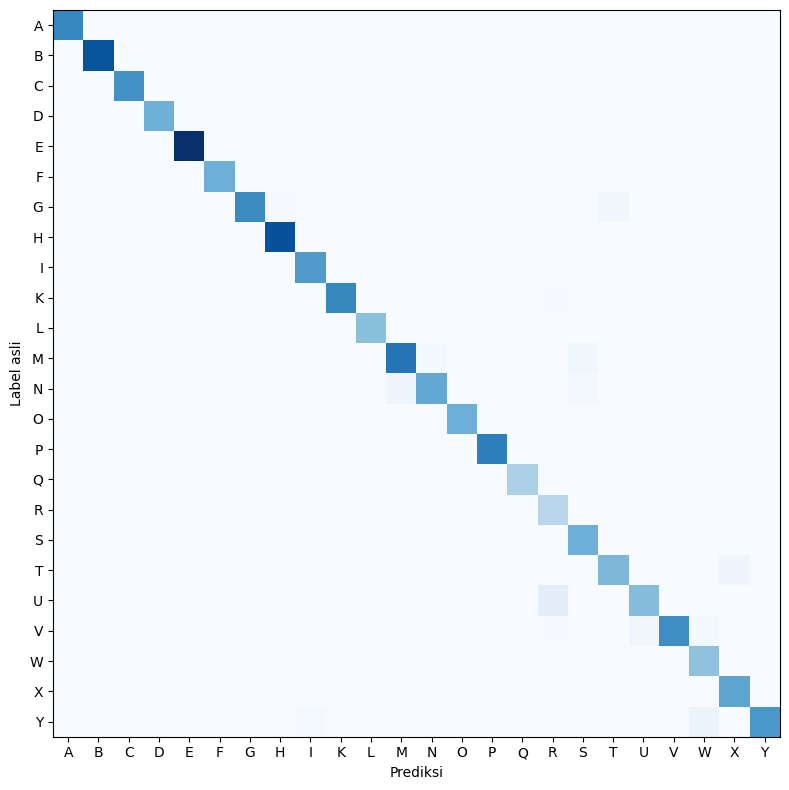

10 kesalahan terbanyak (asli -> prediksi, jumlah):
  U -> R: 49
  Y -> W: 27
  N -> M: 22
  T -> X: 21
  G -> T: 19
  M -> S: 19
  V -> U: 16
  N -> S: 10
  V -> W: 10
  M -> N: 9
Model disimpan: asl_model.joblib


In [ ]:
cm = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(len(names))); ax.set_xticklabels(names)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Label asli"); plt.tight_layout(); plt.show()

off = [(names[i], names[j], cm[i, j]) for i in range(len(names)) for j in range(len(names)) if i != j and cm[i, j] > 0]
print("10 kesalahan terbanyak (asli -> prediksi, jumlah):")
for a, b, n in sorted(off, key=lambda x: -x[2])[:10]:
    print(f"  {a} -> {b}: {n}")

joblib.dump({"model": final, "features": feats, "classes": names, "img": IMG}, "asl_model.joblib")
print("Model disimpan: asl_model.joblib")